In [66]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier

In [67]:
df = pd.read_excel('data.xlsx')
df

,transaction_id,sender_account,receiver_account,sender_country,receiver_country,transaction_amount,currency,transaction_type,transaction_date,transaction_frequency_7d,cash_transaction,offshore_account,politically_exposed_person,shell_company,sanctions_match,customer_risk_score,suspicious_flag
0,AML00001,SA100002,RA200002,MY,IN,20272,MYR,Online Transfer,2026-07-01,7,Yes,No,No,No,No,14,0
1,AML00002,SA100003,RA200003,MY,SG,67010,USD,Wire Transfer,2026-07-02,4,Yes,No,No,No,No,15,0
2,AML00003,SA100004,RA200004,MY,IN,72726,MYR,Cash Deposit,2026-07-03,7,Yes,No,No,No,No,62,0
3,AML00004,SA100005,RA200005,MY,MY,76914,MYR,RTGS,2026-07-04,1,No,No,No,No,No,13,0
4,AML00005,SA100006,RA200006,MY,MY,38459,SGD,Online Transfer,2026-07-05,7,Yes,No,No,No,No,44,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,AML00096,SA100097,RA200097,MY,SG,47704,MYR,SWIFT,2026-07-06,3,Yes,No,No,No,No,15,0
96,AML00097,SA100098,RA200098,MY,MY,58939,MYR,Wire Transfer,2026-07-07,7,No,No,No,No,No,64,0
97,AML00098,SA100099,RA200099,MY,MY,62532,USD,RTGS,2026-07-08,10,No,No,No,No,No,10,0
98,AML00099,SA100100,RA200100,MY,MY,59344,MYR,RTGS,2026-07-09,4,Yes,No,No,No,No,24,0


In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   transaction_id              100 non-null    str  
 1   sender_account              100 non-null    str  
 2   receiver_account            100 non-null    str  
 3   sender_country              100 non-null    str  
 4   receiver_country            100 non-null    str  
 5   transaction_amount          100 non-null    int64
 6   currency                    100 non-null    str  
 7   transaction_type            100 non-null    str  
 8   transaction_date            100 non-null    str  
 9   transaction_frequency_7d    100 non-null    int64
 10  cash_transaction            100 non-null    str  
 11  offshore_account            100 non-null    str  
 12  politically_exposed_person  100 non-null    str  
 13  shell_company               100 non-null    str  
 14  sanctions_match       

In [69]:
df.describe()

,transaction_amount,transaction_frequency_7d,customer_risk_score,suspicious_flag
count,100.000000,100.000000,100.000000,100.000000
mean,136794.830000,13.790000,45.150000,0.180000
std,223077.402517,14.978297,25.339862,0.386123
min,1148.000000,1.000000,10.000000,0.000000
25%,26539.250000,4.000000,24.750000,0.000000
50%,54474.000000,9.000000,41.000000,0.000000
75%,78512.250000,14.000000,59.250000,0.000000
max,899743.000000,67.000000,96.000000,1.000000


In [70]:
df.isnull().sum()

transaction_id                0
sender_account                0
receiver_account              0
sender_country                0
receiver_country              0
transaction_amount            0
currency                      0
transaction_type              0
transaction_date              0
transaction_frequency_7d      0
cash_transaction              0
offshore_account              0
politically_exposed_person    0
shell_company                 0
sanctions_match               0
customer_risk_score           0
suspicious_flag               0
dtype: int64

In [71]:
df.duplicated().sum()

np.int64(0)

In [72]:
binary_cols = ['cash_transaction','offshore_account','politically_exposed_person','shell_company','sanctions_match']
for cols in binary_cols:
    df[cols] = df[cols].astype(str).str.strip().str.lower().map({'yes': 1,'no': 0})

In [73]:
df.head(5)

,transaction_id,sender_account,receiver_account,sender_country,receiver_country,transaction_amount,currency,transaction_type,transaction_date,transaction_frequency_7d,cash_transaction,offshore_account,politically_exposed_person,shell_company,sanctions_match,customer_risk_score,suspicious_flag
0,AML00001,SA100002,RA200002,MY,IN,20272,MYR,Online Transfer,2026-07-01,7,1,0,0,0,0,14,0
1,AML00002,SA100003,RA200003,MY,SG,67010,USD,Wire Transfer,2026-07-02,4,1,0,0,0,0,15,0
2,AML00003,SA100004,RA200004,MY,IN,72726,MYR,Cash Deposit,2026-07-03,7,1,0,0,0,0,62,0
3,AML00004,SA100005,RA200005,MY,MY,76914,MYR,RTGS,2026-07-04,1,0,0,0,0,0,13,0
4,AML00005,SA100006,RA200006,MY,MY,38459,SGD,Online Transfer,2026-07-05,7,1,0,0,0,0,44,0


In [74]:
df = pd.get_dummies(df,columns=['currency','transaction_type','sender_country','receiver_country'],dtype=int)

In [75]:
df.head()

,transaction_id,sender_account,receiver_account,transaction_amount,transaction_date,transaction_frequency_7d,cash_transaction,offshore_account,politically_exposed_person,shell_company,...,transaction_type_SWIFT,transaction_type_Wire Transfer,sender_country_MY,receiver_country_AE,receiver_country_GB,receiver_country_HK,receiver_country_IN,receiver_country_MY,receiver_country_SG,receiver_country_US
0,AML00001,SA100002,RA200002,20272,2026-07-01,7,1,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,AML00002,SA100003,RA200003,67010,2026-07-02,4,1,0,0,0,...,0,1,1,0,0,0,0,0,1,0
2,AML00003,SA100004,RA200004,72726,2026-07-03,7,1,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,AML00004,SA100005,RA200005,76914,2026-07-04,1,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
4,AML00005,SA100006,RA200006,38459,2026-07-05,7,1,0,0,0,...,0,0,1,0,0,0,0,1,0,0


In [76]:
df = df.drop(columns=['transaction_id', 'sender_account', 'receiver_account','transaction_date'])

In [77]:
X = df.drop(columns=['suspicious_flag'])
Y = df['suspicious_flag']

In [78]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

In [79]:
model = RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced')

In [80]:
model.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [81]:
Y_pred = model.predict(X_test)

In [83]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_test, Y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 1.0


In [84]:
from sklearn.metrics import classification_report

print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00         4

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



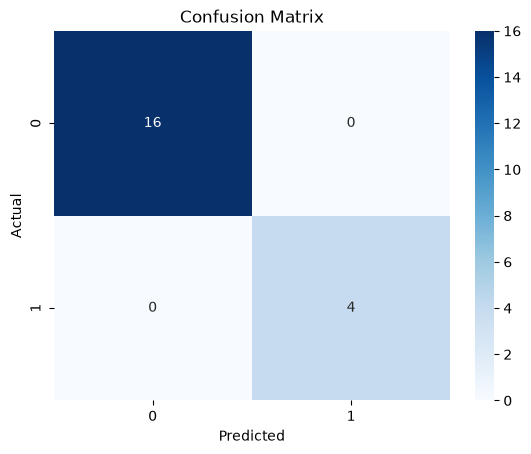

In [87]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, Y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()